In [1]:
import os, glob, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
# INTRO: Vérifie les fichiers et résume la période par département.

DEPARTMENTS = [61, 69]        
DATA_ROOT = "."              

intro_info = {}               # Dictionnaire pour stocker les infos par département

for dept in DEPARTMENTS:
    # Lister les fichiers CSV de chaque station du département
    station_files = glob.glob(f"{DATA_ROOT}/DEPT_{dept}/DEPT_{dept}_STATION_*.csv")
    # Extraire les IDs des stations à partir des noms de fichiers
    station_ids = [os.path.basename(f).split("_STATION_")[1].split(".")[0] for f in station_files]
    periods = []

    # Lire chaque fichier pour déterminer la période temporelle
    for f in station_files:
        df = pd.read_csv(f, sep=";", parse_dates=["AAAAMMJJHH"]) 
        periods.append((df["AAAAMMJJHH"].min(), df["AAAAMMJJHH"].max()))

    # Déterminer la période totale du département
    start = min(p[0] for p in periods)
    end = max(p[1] for p in periods)

    # Sauvegarder les infos récapitulatives
    intro_info[dept] = {
        "stations": station_ids,
        "n_stations": len(station_ids),
        "period_start": start.strftime("%Y-%m-%d"),
        "period_end": end.strftime("%Y-%m-%d")
    }

# Afficher le résumé global des données
print("Dataset Summary")
for dept, info in intro_info.items():
    print(f"\nDepartment {dept}")
    print(f"Stations ({info['n_stations']} total): {', '.join(info['stations'])}")
    print(f"Period: {info['period_start']} - {info['period_end']}")

Dataset Summary

Department 61
Stations (23 total): 61001001, 61006005, 61074004, 61124001, 61133001, 61169003, 61179001, 61214002, 61275001, 61293004, 61328001, 61328002, 61345003, 61369001, 61377001, 61387001, 61404001, 61426001, 61464001, 61479001, 61483002, 61485002, 61491002
Period: 1990-01-01 - 2025-10-12

Department 69
Stations (25 total): 69008001, 69023002, 69028001, 69029001, 69058002, 69066003, 69114001, 69122001, 69123002, 69135001, 69141001, 69174001, 69174002, 69176001, 69196001, 69203001, 69204002, 69206001, 69208001, 69211001, 69238001, 69239002, 69258001, 69264001, 69299001
Period: 1990-01-01 - 2025-10-12


In [3]:
# LOAD DATA: Chargement des données par département

def load_department_data(dept_code):
    data_dict = {}
    # Lister tous les fichiers CSV du département
    files = glob.glob(f"{DATA_ROOT}/DEPT_{dept_code}/DEPT_{dept_code}_STATION_*.csv")

    for f in files:
        # Extraire l'identifiant de la station depuis le nom du fichier
        station_id = int(os.path.basename(f).split("_STATION_")[1].split(".")[0])
        # Lire le fichier et convertir la colonne temporelle
        df = pd.read_csv(f, sep=";", parse_dates=["AAAAMMJJHH"], dayfirst=False)
        # Mettre l'horodatage comme index et trier
        df = df.set_index("AAAAMMJJHH").sort_index()
        # Garder uniquement la température (T) et supprimer les valeurs manquantes
        df = df[["T"]].dropna()
        # Sauvegarder dans le dictionnaire
        data_dict[station_id] = df

    print(f"Department {dept_code}: {len(data_dict)} stations loaded.")
    return data_dict

# Chargement de tous les départements
all_data = {dept: load_department_data(dept) for dept in DEPARTMENTS}

# Vérification sur une station pour chaque département
for dept in DEPARTMENTS:
    sid = list(all_data[dept].keys())[0]
    sample_df = all_data[dept][sid]
    print(f"\nDEPT_{dept}_STATION_{sid}")
    display(sample_df.head())
    display(sample_df.describe())

Department 61: 23 stations loaded.
Department 69: 25 stations loaded.

DEPT_61_STATION_61001001


,T
AAAAMMJJHH,
1990-01-01 00:00:00,-1.4
1990-01-01 01:00:00,-1.5
1990-01-01 02:00:00,-1.7
1990-01-01 03:00:00,-1.8
1990-01-01 04:00:00,-1.7


,T
count,313636.000000
mean,11.207339
std,6.844860
min,-13.300000
25%,6.500000
50%,11.000000
75%,15.800000
max,39.300000



DEPT_69_STATION_69008001


,T
AAAAMMJJHH,
2018-11-19 12:00:00,-0.4
2018-11-19 13:00:00,-1.0
2018-11-19 14:00:00,-1.7
2018-11-19 15:00:00,-1.6
2018-11-19 16:00:00,-1.7


,T
count,60448.000000
mean,11.903949
std,7.919194
min,-8.400000
25%,6.000000
50%,11.500000
75%,17.400000
max,39.600000



DEPT_61_STATION_61001001


,NUM_POSTE,NOM_USUEL,T,T_T,S,R,T_Z
AAAAMMJJHH,,,,,,,
1990-01-01 00:00:00,61001001.0,ALENCON,-1.4,-0.3,0.9,-2.0,-1.842
1990-01-01 01:00:00,61001001.0,ALENCON,-1.5,-0.3,0.7,-1.9,-1.856
1990-01-01 02:00:00,61001001.0,ALENCON,-1.7,-0.3,0.5,-1.9,-1.886
1990-01-01 03:00:00,61001001.0,ALENCON,-1.8,-0.3,0.2,-1.8,-1.900
1990-01-01 04:00:00,61001001.0,ALENCON,-1.7,-0.3,-0.1,-1.3,-1.886


,NUM_POSTE,T,T_T,S,R,T_Z
count,313636.0,313636.000000,313636.000000,313636.000000,313636.000000,313636.000000
mean,61001001.0,11.207339,11.267535,0.000019,-0.060053,-0.000003
std,0.0,6.844860,6.025601,2.867581,1.589760,1.000001
min,61001001.0,-13.300000,-10.000000,-10.900000,-12.000000,-3.580000
25%,61001001.0,6.500000,7.000000,-1.800000,-0.500000,-0.688000
50%,61001001.0,11.000000,11.300000,-0.300000,0.000000,-0.030000
75%,61001001.0,15.800000,15.900000,1.900000,0.500000,0.671000
max,61001001.0,39.300000,28.800000,11.000000,12.400000,4.104000


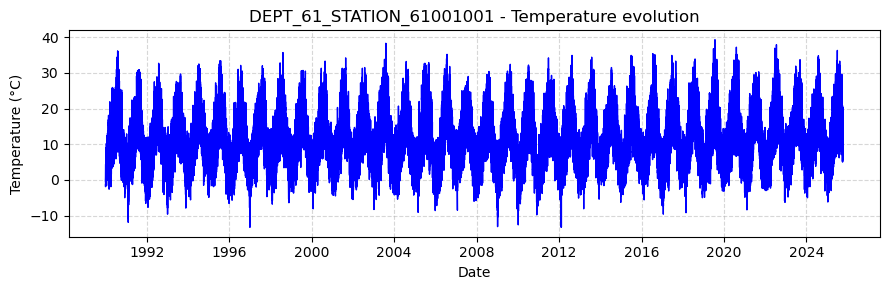

Department 61: no missing values in 23 stations.

DEPT_69_STATION_69008001


,NUM_POSTE,NOM_USUEL,T,T_T,S,R,T_Z
AAAAMMJJHH,,,,,,,
2018-11-19 12:00:00,69008001.0,ANCY_SAPC,-0.4,1.3,1.1,-2.8,-1.554
2018-11-19 13:00:00,69008001.0,ANCY_SAPC,-1.0,1.3,1.1,-3.4,-1.629
2018-11-19 14:00:00,69008001.0,ANCY_SAPC,-1.7,1.3,1.4,-4.4,-1.718
2018-11-19 15:00:00,69008001.0,ANCY_SAPC,-1.6,1.3,1.2,-4.2,-1.705
2018-11-19 16:00:00,69008001.0,ANCY_SAPC,-1.7,1.4,0.7,-3.8,-1.718


,NUM_POSTE,T,T_T,S,R,T_Z
count,60448.0,60448.000000,60448.000000,60448.000000,60448.000000,60448.000000
mean,69008001.0,11.903949,11.842719,0.000008,0.061057,0.000005
std,0.0,7.919194,7.436165,2.379082,1.613507,1.000010
min,69008001.0,-8.400000,-5.900000,-6.200000,-15.800000,-2.564000
25%,69008001.0,6.000000,6.200000,-1.600000,-0.400000,-0.746000
50%,69008001.0,11.500000,11.500000,-0.300000,0.000000,-0.051000
75%,69008001.0,17.400000,17.500000,1.600000,0.500000,0.694000
max,69008001.0,39.600000,30.300000,7.500000,13.100000,3.497000


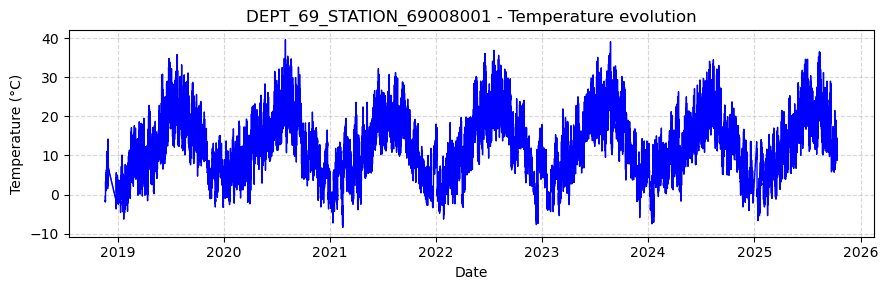

Department 69: no missing values in 25 stations.


In [4]:
# EXPLORATION: Vérification rapide (head, describe, plot, valeurs manquantes)

for dept in DEPARTMENTS:
    # Lister les fichiers du département
    files = glob.glob(f"{DATA_ROOT}/DEPT_{dept}/DEPT_{dept}_STATION_*.csv")
    if not files:
        print(f"No files found for Department {dept}.")
        continue

    # Sélection d'un fichier exemple (le premier) pour chaque département
    example_file = files[0]
    df_example = pd.read_csv(example_file, sep=";", parse_dates=["AAAAMMJJHH"])
    df_example = df_example.set_index("AAAAMMJJHH").sort_index()

    # Identifier le nom du fichier (donne aussi l'ID de la station)
    station_name = os.path.basename(example_file).split(".")[0]

    print(f"\n{station_name}")
    display(df_example.head())
    display(df_example.describe())

    # Visualisation simple de la température pour l'exemple
    plt.figure(figsize=(9, 3))
    plt.plot(df_example.index, df_example["T"], color="blue", linewidth=1)
    plt.title(f"{station_name} - Temperature evolution")
    plt.xlabel("Date")
    plt.ylabel("Temperature (°C)")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

    # Contrôle des valeurs manquantes pour toutes les stations du département
    total_stations = 0
    stations_with_missing = 0
    total_missing_values = 0

    for f in files:
        df = pd.read_csv(f, sep=";", parse_dates=["AAAAMMJJHH"])
        total_stations += 1
        na_count = df["T"].isna().sum()
        total_missing_values += na_count
        if na_count > 0:
            stations_with_missing += 1
            print(f"Missing values in {os.path.basename(f)} : {na_count}")

    if stations_with_missing == 0:
        print(f"Department {dept}: no missing values in {total_stations} stations.")
    else:
        print(f"Department {dept}: {stations_with_missing}/{total_stations} stations contain missing values "
              f"({total_missing_values} total NaNs).")

Department 61: feature engineering completed for 23 stations.
Department 69: feature engineering completed for 25 stations.

DEPT_61_STATION_61001001
Columns: ['T', 'hour', 'day', 'month', 'weekday', 'sin_hour', 'cos_hour', 'T_lag1', 'T_lag24', 'T_rollmean_24']


,T,hour,day,month,weekday,sin_hour,cos_hour,T_lag1,T_lag24,T_rollmean_24
AAAAMMJJHH,,,,,,,,,,
1990-01-02 00:00:00,1.8,0,2,1,1,0.000000,1.000000,1.5,-1.4,-0.595833
1990-01-02 01:00:00,1.4,1,2,1,1,0.258819,0.965926,1.8,-1.5,-0.475000
1990-01-02 02:00:00,1.0,2,2,1,1,0.500000,0.866025,1.4,-1.7,-0.362500
1990-01-02 03:00:00,0.6,3,2,1,1,0.707107,0.707107,1.0,-1.8,-0.262500
1990-01-02 04:00:00,0.2,4,2,1,1,0.866025,0.500000,0.6,-1.7,-0.183333



DEPT_69_STATION_69008001
Columns: ['T', 'hour', 'day', 'month', 'weekday', 'sin_hour', 'cos_hour', 'T_lag1', 'T_lag24', 'T_rollmean_24']


,T,hour,day,month,weekday,sin_hour,cos_hour,T_lag1,T_lag24,T_rollmean_24
AAAAMMJJHH,,,,,,,,,,
2018-11-20 12:00:00,2.5,12,20,11,1,1.224647e-16,-1.000000,0.3,-0.4,-1.300000
2018-11-20 13:00:00,2.6,13,20,11,1,-2.588190e-01,-0.965926,2.5,-1.0,-1.150000
2018-11-20 14:00:00,3.3,14,20,11,1,-5.000000e-01,-0.866025,2.6,-1.7,-0.941667
2018-11-20 15:00:00,3.2,15,20,11,1,-7.071068e-01,-0.707107,3.3,-1.6,-0.741667
2018-11-20 16:00:00,2.6,16,20,11,1,-8.660254e-01,-0.500000,3.2,-1.7,-0.562500


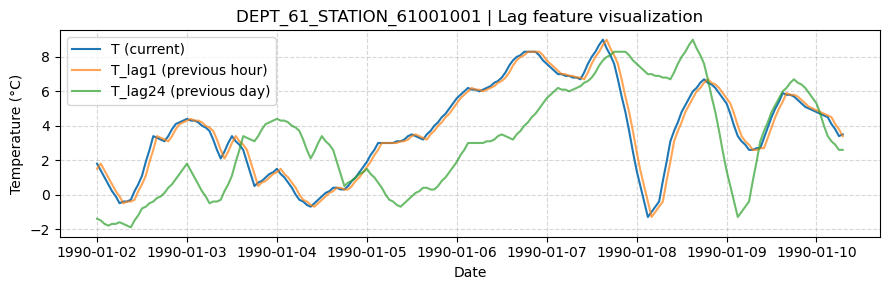

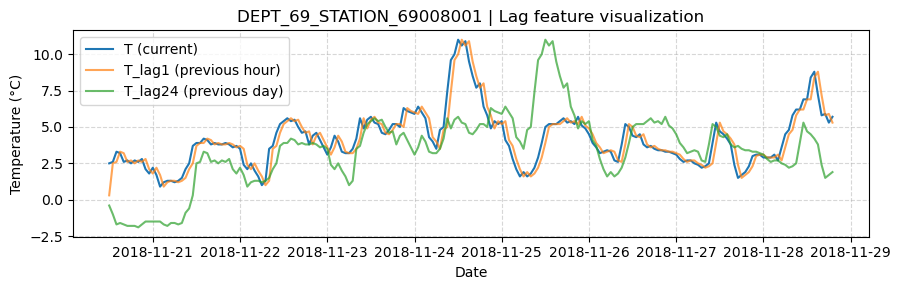

In [5]:
# FEATURE ENGINEERING: Ajout de nouvelles caractéristiques temporelles et de décalage

# Fonction pour extraire les caractéristiques temporelles
def add_time_features(df):
    df = df.copy()
    df["hour"] = df.index.hour
    df["day"] = df.index.day
    df["month"] = df.index.month
    df["weekday"] = df.index.weekday

    # Encodage du cycle journalier (important pour la périodicité)
    df["sin_hour"] = np.sin(2 * np.pi * df["hour"] / 24)
    df["cos_hour"] = np.cos(2 * np.pi * df["hour"] / 24)

    return df

# Fonction pour ajouter les variables retardées (lags)
def add_lag_features(df):
    df = df.copy()
    df["T_lag1"] = df["T"].shift(1)
    df["T_lag24"] = df["T"].shift(24)
    df["T_rollmean_24"] = df["T"].rolling(window=24).mean()
    df.dropna(inplace=True)
    return df

# Application des fonctions à toutes les stations
all_data_fe = {}
for dept, stations in all_data.items():
    all_data_fe[dept] = {}
    for sid, df in stations.items():
        df_fe = add_time_features(df)
        df_fe = add_lag_features(df_fe)
        all_data_fe[dept][sid] = df_fe
    print(f"Department {dept}: feature engineering completed for {len(stations)} stations.")

# Aperçu de deux exemples (départements 61 et 69)
for dept in [61, 69]:
    sid = list(all_data_fe[dept].keys())[0]
    sample_df = all_data_fe[dept][sid]
    print(f"\nDEPT_{dept}_STATION_{sid}")
    print("Columns:", list(sample_df.columns))
    display(sample_df.head())

# Visualisation des lag features
for dept in [61, 69]:
    sid = list(all_data_fe[dept].keys())[0]
    df_vis = all_data_fe[dept][sid].iloc[:200] 
    plt.figure(figsize=(9, 3))
    plt.plot(df_vis.index, df_vis["T"], label="T (current)", linewidth=1.5)
    plt.plot(df_vis.index, df_vis["T_lag1"], label="T_lag1 (previous hour)", alpha=0.7)
    plt.plot(df_vis.index, df_vis["T_lag24"], label="T_lag24 (previous day)", alpha=0.7)
    plt.title(f"DEPT_{dept}_STATION_{sid} | Lag feature visualization")
    plt.xlabel("Date")
    plt.ylabel("Temperature (°C)")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [6]:
# TRAIN TEST SPLIT: Séparation chronologique des données (train/test)
# On divise chaque série en partie train (80%) et test (20%) sans mélanger l’ordre temporel.

def time_series_split(df, train_ratio=0.8):
    df = df.copy()
    
    # Vérifie qu’il y a assez de données pour faire le split
    if len(df) < 30:
        raise ValueError("Station dataset too short for time-series split.")

    # Découpage en respectant la chronologie
    n_train = int(len(df) * train_ratio)
    train = df.iloc[:n_train]
    test = df.iloc[n_train:]

    # Variables explicatives (X) et variable cible (y)
    X_train = train.drop(columns=["T"])
    y_train = train["T"]
    X_test = test.drop(columns=["T"])
    y_test = test["T"]

    return X_train, X_test, y_train, y_test

# Application du split à tous les départements
splits = {}

for dept, stations in all_data_fe.items():
    splits[dept] = {}
    for sid, df in stations.items():
        X_train, X_test, y_train, y_test = time_series_split(df)
        splits[dept][sid] = {
            "X_train": X_train, "X_test": X_test,
            "y_train": y_train, "y_test": y_test,
            "train_period": (X_train.index.min(), X_train.index.max()),
            "test_period": (X_test.index.min(), X_test.index.max())
        }
    print(f"Department {dept}: time split completed for {len(stations)} stations.")


# Vérification sur les départements 61 et 69
for dept in [61, 69]:
    sid = list(splits[dept].keys())[0]
    split_info = splits[dept][sid]

    print(f"\nDEPT_{dept}_STATION_{sid}")
    print(f"Train size: {len(split_info['X_train'])}, Test size: {len(split_info['X_test'])}")
    print(f"Train period: {split_info['train_period'][0]} - {split_info['train_period'][1]}")
    print(f"Test period:  {split_info['test_period'][0]} - {split_info['test_period'][1]}")

    # Vérification qu'il n'y a pas de chevauchement
    assert split_info["X_train"].index.max() < split_info["X_test"].index.min(), \
        "Overlap detected between train and test sets"

Department 61: time split completed for 23 stations.
Department 69: time split completed for 25 stations.

DEPT_61_STATION_61001001
Train size: 250889, Test size: 62723
Train period: 1990-01-02 00:00:00 - 2018-08-16 16:00:00
Test period:  2018-08-16 17:00:00 - 2025-10-12 03:00:00

DEPT_69_STATION_69008001
Train size: 48339, Test size: 12085
Train period: 2018-11-20 12:00:00 - 2024-05-26 14:00:00
Test period:  2024-05-26 15:00:00 - 2025-10-12 03:00:00


In [7]:
# MODEL TRAINING: Entraînement des modèles (LR et RF)
# On entraîne deux modèles : Régression Linéaire et Forêt Aléatoire pour chaque station.

# Régression Linéaire 
def train_linear_regression(X_train, X_test, y_train, y_test):
    model = LinearRegression()           # Modèle simple et rapide
    model.fit(X_train, y_train)          # Apprentissage
    y_pred = model.predict(X_test)       # Prédictions
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    return model, y_pred, mse, r2

# Forêt Aléatoire
def train_random_forest(X_train, X_test, y_train, y_test):
    model = RandomForestRegressor(
        n_estimators=150,                # 150 arbres
        max_depth=12,                    # profondeur max
        min_samples_leaf=3,              # feuilles minimales
        random_state=58,                 # pour reproductibilité
        n_jobs=-1                        # utilise tous les coeurs CPU
    )
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    return model, y_pred, mse, r2

# Entraînement des modèles pour chaque station
results = {}

for dept, stations in splits.items():
    results[dept] = {}
    print(f"\nDepartment {dept}")

    for sid, split_info in stations.items():
        X_train = split_info["X_train"]
        X_test = split_info["X_test"]
        y_train = split_info["y_train"]
        y_test = split_info["y_test"]

        # Entraînement du modèle linéaire
        lr_model, y_pred_lr, mse_lr, r2_lr = train_linear_regression(X_train, X_test, y_train, y_test)

        # Entraînement du modèle de forêt aléatoire
        rf_model, y_pred_rf, mse_rf, r2_rf = train_random_forest(X_train, X_test, y_train, y_test)

        # Sauvegarde des résultats pour la station
        results[dept][sid] = {
            "lr_model": lr_model, "rf_model": rf_model,
            "y_test": y_test, "y_pred_lr": y_pred_lr, "y_pred_rf": y_pred_rf,
            "mse_lr": mse_lr, "r2_lr": r2_lr,
            "mse_rf": mse_rf, "r2_rf": r2_rf
        }

        print(f"DEPT_{dept}_STATION_{sid} training done.")


Department 61
DEPT_61_STATION_61001001 training done.
DEPT_61_STATION_61006005 training done.
DEPT_61_STATION_61074004 training done.
DEPT_61_STATION_61124001 training done.
DEPT_61_STATION_61133001 training done.
DEPT_61_STATION_61169003 training done.
DEPT_61_STATION_61179001 training done.
DEPT_61_STATION_61214002 training done.
DEPT_61_STATION_61275001 training done.
DEPT_61_STATION_61293004 training done.
DEPT_61_STATION_61328001 training done.
DEPT_61_STATION_61328002 training done.
DEPT_61_STATION_61345003 training done.
DEPT_61_STATION_61369001 training done.
DEPT_61_STATION_61377001 training done.
DEPT_61_STATION_61387001 training done.
DEPT_61_STATION_61404001 training done.
DEPT_61_STATION_61426001 training done.
DEPT_61_STATION_61464001 training done.
DEPT_61_STATION_61479001 training done.
DEPT_61_STATION_61483002 training done.
DEPT_61_STATION_61485002 training done.
DEPT_61_STATION_61491002 training done.

Department 69
DEPT_69_STATION_69008001 training done.
DEPT_69_ST


DEPT_61_STATION_61001001
Linear Regression : MSE=0.763, R²=0.984
Random Forest     : MSE=0.586, R²=0.987


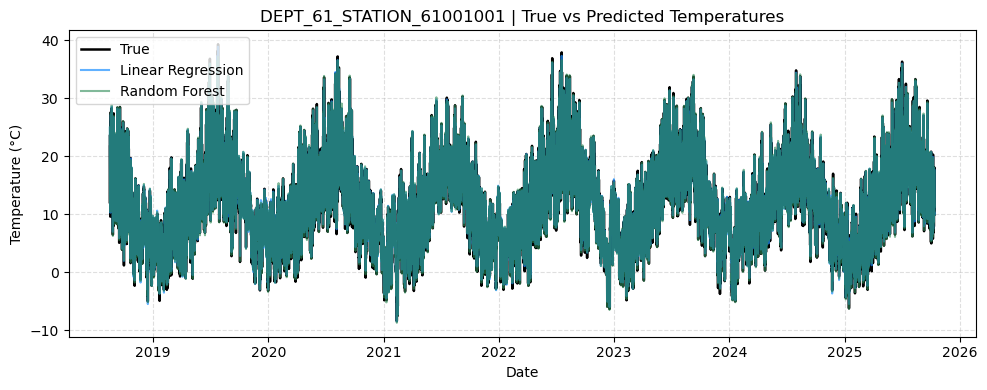


DEPT_61_STATION_61006005
Linear Regression : MSE=0.862, R²=0.981
Random Forest     : MSE=0.668, R²=0.986


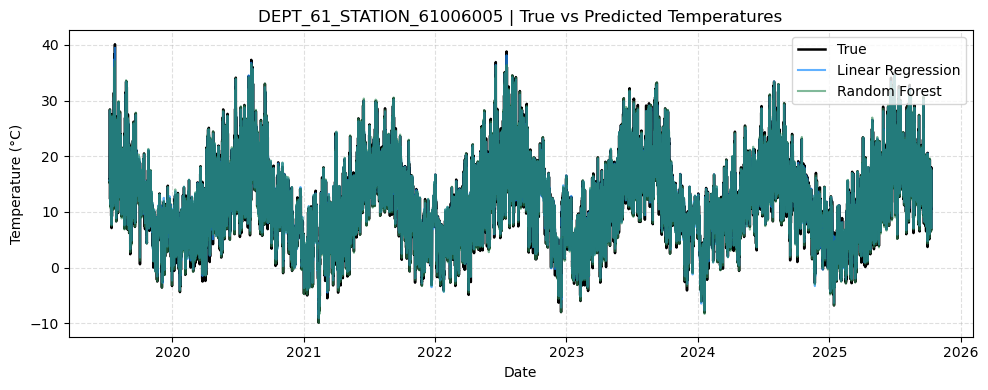


DEPT_69_STATION_69008001
Linear Regression : MSE=0.914, R²=0.985
Random Forest     : MSE=0.811, R²=0.987


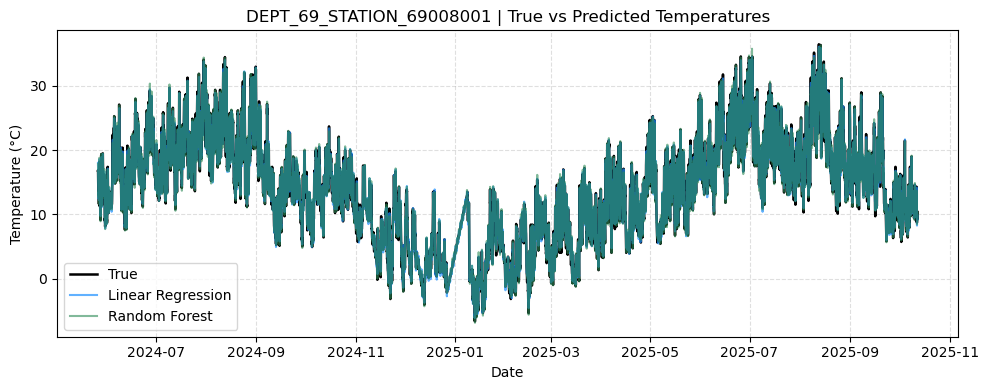


DEPT_69_STATION_69023002
Linear Regression : MSE=0.743, R²=0.988
Random Forest     : MSE=0.646, R²=0.989


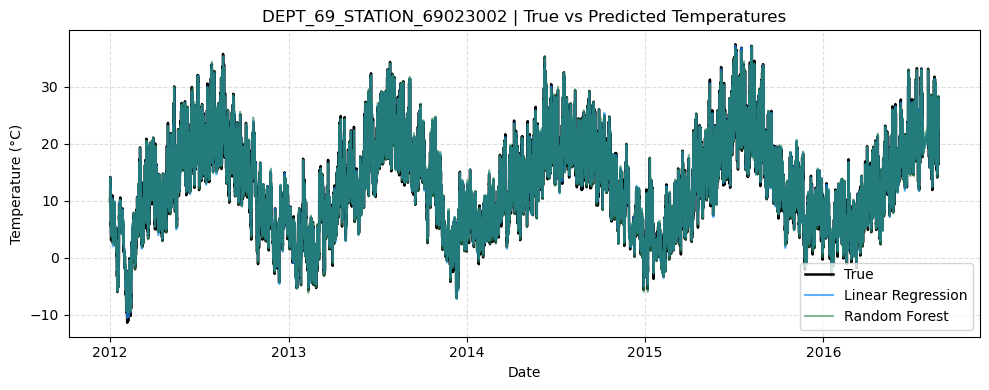

In [8]:
# EVALUATION: Courbe y_test vs y_pred (overlay) pour une période représentative
# On compare les valeurs réelles et prédites (LR et RF) sur le même graphique.

def plot_predictions(y_test, y_pred_lr, y_pred_rf, dept, sid):
    plt.figure(figsize=(10, 4))
    plt.plot(y_test.index, y_test, label="True", color="black", linewidth=1.8)
    plt.plot(y_test.index, y_pred_lr, label="Linear Regression", color="dodgerblue", alpha=0.7)
    plt.plot(y_test.index, y_pred_rf, label="Random Forest", color="seagreen", alpha=0.6)
    plt.title(f"DEPT_{dept}_STATION_{sid} | True vs Predicted Temperatures")
    plt.xlabel("Date")
    plt.ylabel("Temperature (°C)")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

# Exemple
for dept in [61, 69]:
    station_ids = list(results[dept].keys())[:2] 
    for sid in station_ids:
        res = results[dept][sid]
        print(f"\nDEPT_{dept}_STATION_{sid}")
        print(f"Linear Regression : MSE={res['mse_lr']:.3f}, R²={res['r2_lr']:.3f}")
        print(f"Random Forest     : MSE={res['mse_rf']:.3f}, R²={res['r2_rf']:.3f}")
        plot_predictions(res["y_test"], res["y_pred_lr"], res["y_pred_rf"], dept, sid)

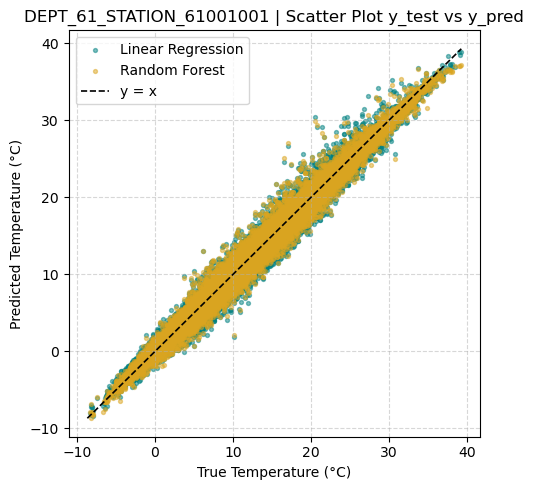

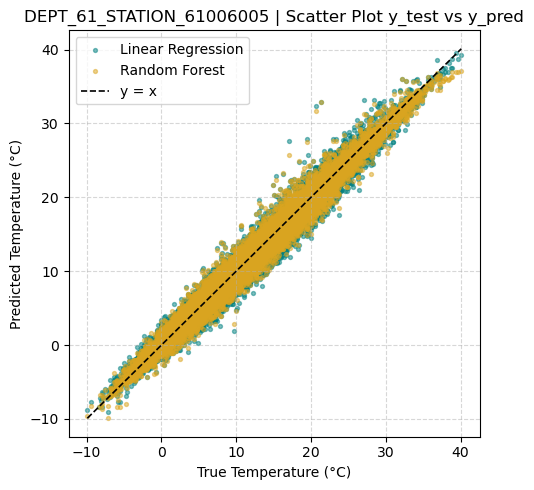

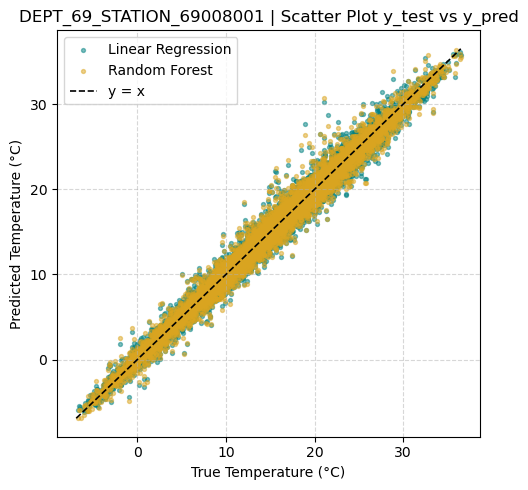

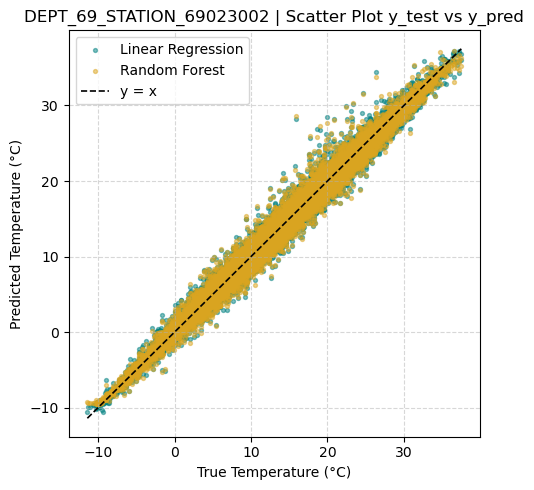

In [9]:
# EVALUATION: Scatter plot y_test vs y_pred + ligne y=x
# On visualise la corrélation entre les valeurs réelles et prédites pour les deux modèles.

def plot_scatter(y_test, y_pred_lr, y_pred_rf, dept, sid):
    plt.figure(figsize=(5, 5))
    plt.scatter(y_test, y_pred_lr, s=8, alpha=0.5, color="teal", label="Linear Regression")
    plt.scatter(y_test, y_pred_rf, s=8, alpha=0.5, color="goldenrod", label="Random Forest")
    lims = [min(y_test.min(), y_pred_lr.min(), y_pred_rf.min()),
            max(y_test.max(), y_pred_lr.max(), y_pred_rf.max())]
    plt.plot(lims, lims, "k--", linewidth=1.2, label="y = x")
    plt.title(f"DEPT_{dept}_STATION_{sid} | Scatter Plot y_test vs y_pred")
    plt.xlabel("True Temperature (°C)")
    plt.ylabel("Predicted Temperature (°C)")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

for dept in [61, 69]:
    for sid in list(results[dept].keys())[:2]:   
        res = results[dept][sid]
        plot_scatter(res["y_test"], res["y_pred_lr"], res["y_pred_rf"], dept, sid)

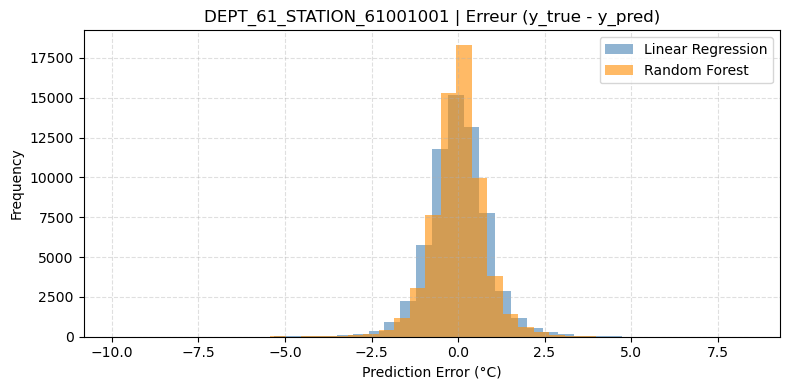

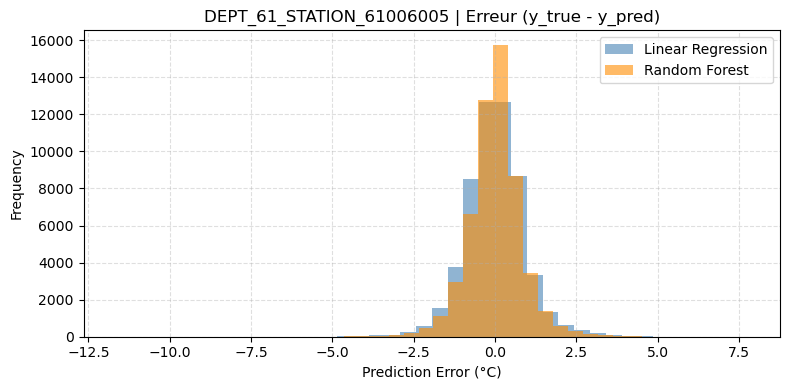

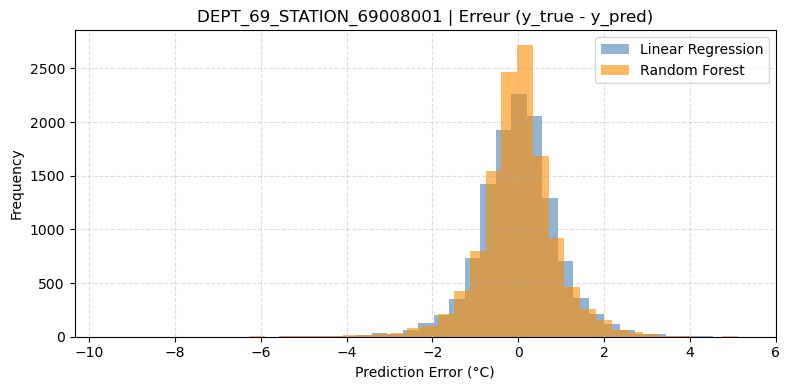

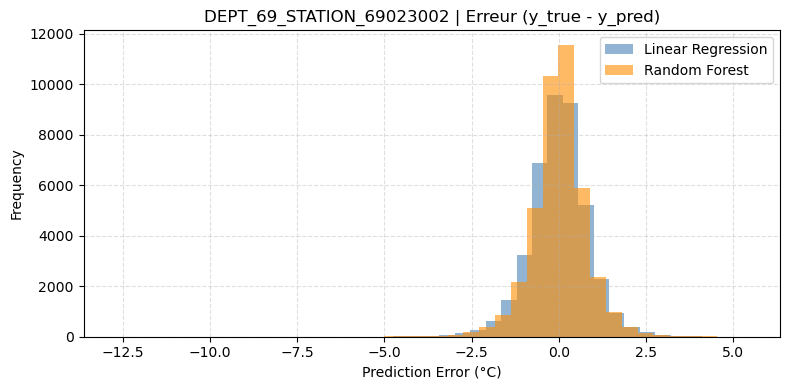

In [10]:
# EVALUATION: Histogramme des erreurs (y_test - y_pred)
# On visualise la distribution des erreurs pour les deux modèles (LR et RF).

def plot_error_hist(y_test, y_pred_lr, y_pred_rf, dept, sid):
    plt.figure(figsize=(8, 4))
    plt.hist(y_test - y_pred_lr, bins=40, alpha=0.6, label="Linear Regression", color="steelblue")
    plt.hist(y_test - y_pred_rf, bins=40, alpha=0.6, label="Random Forest", color="darkorange")
    plt.title(f"DEPT_{dept}_STATION_{sid} | Erreur (y_true - y_pred)")
    plt.xlabel("Prediction Error (°C)")
    plt.ylabel("Frequency")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

# Exemple
for dept in [61, 69]:
    for sid in list(results[dept].keys())[:2]:
        res = results[dept][sid]
        plot_error_hist(res["y_test"], res["y_pred_lr"], res["y_pred_rf"], dept, sid)

In [11]:
# SAVE RESULTS: Sauvegarde des modèles et des résultats par département
# On enregistre les modèles (LR et RF) et les métriques pour chaque station et département.

BASE_SAVE_DIR = "."

for dept, stations in results.items():
    # Créer un dossier PKL pour chaque département
    dept_pkl_dir = os.path.join(BASE_SAVE_DIR, f"DEPT_{dept}_PKL")
    os.makedirs(dept_pkl_dir, exist_ok=True)

    dept_records = []

    for sid, res in stations.items():
        # Enregistrer les métriques pour chaque station
        dept_records.append({
            "station_id": sid,
            "mse_lr": res["mse_lr"],
            "r2_lr": res["r2_lr"],
            "mse_rf": res["mse_rf"],
            "r2_rf": res["r2_rf"]
        })

        # Sauvegarder les modèles LR et RF dans le dossier du département
        lr_path = os.path.join(dept_pkl_dir, f"DEPT_{dept}_STATION_{sid}_LR.pkl")
        rf_path = os.path.join(dept_pkl_dir, f"DEPT_{dept}_STATION_{sid}_RF.pkl")

        joblib.dump(res["lr_model"], lr_path)
        joblib.dump(res["rf_model"], rf_path)

    # Créer un fichier CSV récapitulatif pour le département
    dept_df = pd.DataFrame(dept_records)
    dept_csv_path = os.path.join(BASE_SAVE_DIR, f"local_results_DEPT_{dept}_TP02.csv")
    dept_df.to_csv(dept_csv_path, index=False)

    # Affichage du résumé
    print(f"\nDepartment {dept}")
    print(f"Models saved under:   '{dept_pkl_dir}/'")
    print(f"CSV summary:          '{dept_csv_path}'")
    display(dept_df)


Department 61
Models saved under:   '.\DEPT_61_PKL/'
CSV summary:          '.\local_results_DEPT_61_TP02.csv'


,station_id,mse_lr,r2_lr,mse_rf,r2_rf
0,61001001,0.763295,0.983719,0.586297,0.987494
1,61006005,0.861720,0.981310,0.668023,0.985511
2,61074004,0.718636,0.984946,0.591654,0.987606
3,61124001,0.419685,0.945926,0.448836,0.942170
4,61133001,0.613606,0.985923,0.507388,0.988360
5,61169003,0.946362,0.977838,0.743372,0.982592
6,61179001,0.636093,0.984668,0.511883,0.987662
7,61214002,0.842546,0.982050,0.652055,0.986108
8,61275001,0.739196,0.983825,0.593816,0.987006
9,61293004,0.523308,0.988706,0.439941,0.990505



Department 69
Models saved under:   '.\DEPT_69_PKL/'
CSV summary:          '.\local_results_DEPT_69_TP02.csv'


,station_id,mse_lr,r2_lr,mse_rf,r2_rf
0,69008001,0.913863,0.985229,0.810864,0.986893
1,69023002,0.742821,0.987536,0.646331,0.989155
2,69028001,1.064013,0.984468,0.842994,0.987695
3,69029001,0.841664,0.987661,0.669914,0.990179
4,69058002,0.743562,0.987297,0.660271,0.988720
5,69066003,1.021034,0.982135,0.885969,0.984498
6,69114001,0.984968,0.984698,0.775339,0.987955
7,69122001,0.997360,0.983320,0.836294,0.986014
8,69123002,0.713795,0.989304,0.575561,0.991376
9,69135001,1.107760,0.983206,0.940331,0.985744
